#### Chatbot with The Tool

In [99]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
from langgraph.graph import add_messages
from langchain_core.prompts import message
from typing import TypedDict,Annotated

class state():
    messages : Annotated[list,add_messages]

In [101]:
llm_invokes=init_chat_model(
    "openai/gpt-oss-20b",
    model_provider="groq"
)

In [38]:
from langchain_tavily import TavilySearch

tool1_model = TavilySearch(max_results=2)
tool1_model.invoke("give me recent Ai news")

{'query': 'give me recent Ai news',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.artificialintelligence-news.com',
   'title': 'AI News | Latest News | Insights Powering AI-Driven Business ...',
   'content': 'October 30, 2025\n\n### Malaysia launches Ryt Bank, its first AI-powered bank\n\nFinance AI\n\nAugust 26, 2025\n\n### Google’s Veo 3 AI video creation tools are now widely available\n\nAI in Action\n\nJuly 29, 2025\n\n#### Computer Vision\n\n### Microsoft’s Majorana 2 quantum chip is also a case study for agentic AI in R&D\n\nInside AI\n\nJune 3, 2026\n\n### US and Japan announce sweeping AI and tech collaboration\n\nArtificial Intelligence\n\nApril 11, 2024\n\n### UK and Canada sign AI compute agreement [...] August 18, 2026\n\n### Okta targets AI agent token costs with MCP scoping\n\nData Engineering & MLOps\n\nAugust 13, 2026\n\n### Red Hat, NVIDIA, IBM back project turning AI policy into code\n\nGovernance, Regulation & Polic

In [39]:
# custmom function
def multiply(a:int,b:int) -> int:
    """
    multiply a and b 

    a is int
    b is int

    a is first argument
    b is secound argument

    return : 
    int output
    
    """
    return a * b    

In [40]:
tools=[tool1_model,multiply]
llm_with_tool=llm_invokes.bind_tools(tools)

In [41]:
print(type(llm_with_tool))
print(llm_with_tool)

<class 'langchain_core.language_models.chat_models._ChatModelBinding'>
bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.1', 'langchain': '1.4.0'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015AE6C61B80>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015AE6C62330>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')) kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A searc

In [42]:
def llm_tool_calling(state:state):
    # print(state["messages"]) 
    response=llm_with_tool.invoke(state["messages"])
    return {"messages":response}

In [43]:
from langgraph.graph import START,END,StateGraph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
graph_builder=StateGraph(state)

graph_builder.add_edge(START,"llm_tool_calling")
graph_builder.add_node("llm_tool_calling",llm_tool_calling)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_conditional_edges(
    "llm_tool_calling",
    tools_condition
)
graph_builder.add_edge("tools",END)
graph=graph_builder.compile()

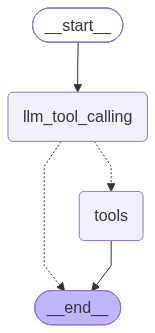

In [44]:
graph

In [45]:
response=graph.invoke({
    "messages":"give me the recent AI news  and  what is 2 multipy 2?"
    })
len(response["messages"])
print(type(response["messages"]))
response["messages"][-1].content


<class 'list'>


'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, September 8: Top Stories | AI Weekly", "content": "NYU mathematician Tristan Buckmaster and Anthropic researcher Levent Alpöge on Sept 8 released a Lean-verified proof of finite-time blowup for the 3D incompressible Euler equations under smooth forcing, extending Córdoba and Martínez-Zoroa\'s earlier rougher-forcing result and using Claude and Codex to draft candidate arguments. In an accompanying statement, Buckmaster says rumors of the work reached OpenAI on Sept 3 and that Sébastien Bubeck told him on two Sept 6 calls an internal OpenAI model had produced a roughly 100-page proof for forced Navier-Stokes, proposing arrangements Buckmaster says would have stripped Alpöge from authorship over his Anthropic affiliation. Bubeck publicly called the allegations \'false and inflammatory\' and promised a fuller reply. [...]

In [46]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give me the recent AI news  and  what is 2 multipy 2?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a01fc6e5-ff5c-4047-a15c-6ee30247679f)
 Call ID: fc_a01fc6e5-ff5c-4047-a15c-6ee30247679f
  Args:
    query: recent AI news
    search_depth: advanced
    time_range: week
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, September 8: Top Stories | AI Weekly", "content": "NYU mathematician Tristan Buckmaster and Anthropic researcher Levent Alpöge on Sept 8 released a Lean-verified proof of finite-time blowup for the 3D incompressible Euler equations under smooth forcing, extending Córdoba and Martínez-Zoroa'

# React Agent

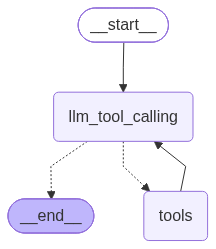

In [47]:
graph_builder=StateGraph(state)

graph_builder.add_edge(START,"llm_tool_calling")
graph_builder.add_node("llm_tool_calling",llm_tool_calling)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_conditional_edges(
    "llm_tool_calling",
    tools_condition
)
graph_builder.add_edge("tools","llm_tool_calling")
graph=graph_builder.compile()
graph

In [48]:
response=graph.invoke({
    "messages":"give me the recent AI news  and  what is 2 multipy 2?"
    })
print(response)
for m in response["messages"]:
    m.pretty_print()


{'messages': [HumanMessage(content='give me the recent AI news  and  what is 2 multipy 2?', additional_kwargs={}, response_metadata={}, id='f5584803-7a93-42e2-b427-8126a699c7f4'), AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks for two things: recent AI news and the result of 2 multiplied by 2. We need to provide recent AI news. We should use the tavily_search tool to get recent AI news. We also need to multiply 2 * 2. We can do that directly or use the multiply function. The multiply function is defined, so we should call it. Let\'s use the tavily_search to get recent AI news. Use query "recent AI news" with maybe search_depth advanced.', 'tool_calls': [{'id': 'fc_b3581d4c-9bea-47c5-9d25-b97a00eb9190', 'function': {'arguments': '{"query":"recent AI news","search_depth":"advanced","topic":"general"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 139, 'prompt_tokens': 380, 'total_tokens': 519, 'comp

### Adding memory in Agentic Graph

In [49]:
response=graph.invoke({
    "messages":"Hello My name is Ravi"
    })
print(response)
for m in response["messages"]:
    m.pretty_print()

{'messages': [HumanMessage(content='Hello My name is Ravi', additional_kwargs={}, response_metadata={}, id='6481e239-ca1e-4394-a4ed-2910d9f5a0ed'), AIMessage(content='Hello Ravi! Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'User: "Hello My name is Ravi". We need to greet. Probably respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 367, 'total_tokens': 410, 'completion_time': 0.046066455, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.017890633, 'prompt_tokens_details': None, 'queue_time': 0.340795625, 'total_time': 0.063957088}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_99996fee8e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a083dd-6159-7a23-8ab6-a1095b73b3d2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 367, 'output_tokens': 43, 'total_tokens': 410, 'output

In [50]:
response=graph.invoke({
    "messages":"what is My name ?"
    })
print(response)
for m in response["messages"]:
    m.pretty_print()

{'messages': [HumanMessage(content='what is My name ?', additional_kwargs={}, response_metadata={}, id='de6315d8-5600-4e22-9551-4b0661c5e6a5'), AIMessage(content='I’m not sure what you’re asking. Could you clarify? If you’re looking for a reminder of something you told me earlier, I don’t have a record of your name. If you’d like to share it, I’ll remember it for this conversation.', additional_kwargs={'reasoning_content': 'User asks "what is My name?" Probably they want to know what their name is? But we don\'t know. Maybe they want to see the question: "What is my name?" We could respond asking for clarification. There\'s no context. So respond politely asking what they mean.'}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 367, 'total_tokens': 486, 'completion_time': 0.127888237, 'completion_tokens_details': {'reasoning_tokens': 57}, 'prompt_time': 0.032028853, 'prompt_tokens_details': None, 'queue_time': 0.414480764, 'total_time': 0.15991709}, 'model

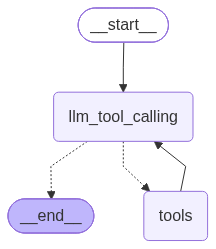

In [54]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

graph_builder=StateGraph(state)

graph_builder.add_edge(START,"llm_tool_calling")
graph_builder.add_node("llm_tool_calling",llm_tool_calling)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_conditional_edges(
    "llm_tool_calling",
    tools_condition
)
graph_builder.add_edge("tools","llm_tool_calling")
graph=graph_builder.compile(checkpointer=memory)
graph

In [57]:
config = {"configurable":{"thread_id":"1"}}

In [59]:
response=graph.invoke({
    "messages":"my name is ravi"
},config=config)

response["messages"][-1].content

'Got it, Ravi! How can I assist you today?'

In [60]:
response=graph.invoke({
    "messages":"what is my name ?"
},config=config)

response["messages"][-1].content

'Your name is Ravi.'

### Streming
Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.
updates : This streams updates to the state of the graph after each node is called
# Before:
using 

##### 1 ) Value
"""
["Hi"]

New message:
"Hello"

values:
["Hi", "Hello"]

New message:
"How are you?"

values:
["Hi", "Hello", "How are you?"]
##### 2) update

Gives ONLY the latest/new thing that was added.

First update:
"Hello"

Second update:
"How are you?"

##### 3) messages

you receive pieces while the LLM is generating:
Hello
Hello bro
Hello bro,
Hello bro, how
Hello bro, how are
Hello bro, how are you?
"""

In [152]:
from langgraph.checkpoint.memory import InMemorySaver
memory = InMemorySaver()

In [169]:
class state(TypedDict):
    messages: Annotated[list,add_messages]

In [170]:
def superbot(state:state):
    response=llm_invokes.invoke(state["messages"])
    return {"messages": [response]}

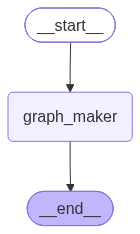

In [171]:
graph_maker=StateGraph(state)
graph_maker.add_edge(START,"graph_maker")
graph_maker.add_node("graph_maker",superbot)
graph_maker.add_edge("graph_maker",END)
graph=graph_maker.compile(checkpointer=memory)
graph

In [172]:
config={"configurable":{"thread_id":"user2"}}

In [173]:
for l in graph.stream({"messages":"what is ML?"},config=config,stream_mode="updates"):
    print(l)

{'graph_maker': {'messages': [AIMessage(content='**ML = Machine Learning** – the science and engineering of building systems that can *learn* from data rather than being explicitly programmed for every task.\n\n---\n\n### 1. Core Idea\n- **Learning from data**: A machine learning algorithm observes examples (inputs and outputs) and automatically discovers patterns or rules that map new inputs to desired outputs.\n- **Adaptivity**: Once trained, the model can improve or adjust as it receives more data or as the underlying data distribution shifts.\n\n### 2. How It Works (High‑Level Pipeline)\n\n| Step | What Happens | Typical Techniques |\n|------|--------------|--------------------|\n| **Data collection** | Gather raw observations (images, text, sensor readings, etc.) | Surveys, sensors, web scraping |\n| **Pre‑processing** | Clean, normalize, encode, and augment data | Imputation, scaling, tokenization |\n| **Model selection** | Choose an algorithm that fits the problem | Linear regre

In [174]:
for l in graph.stream({"messages":"what is AI?"},config=config,stream_mode="values"):
    print(l)

{'messages': [HumanMessage(content='what is ML?', additional_kwargs={}, response_metadata={}, id='25a84950-207f-4fd4-a905-c391134f5bdc'), AIMessage(content='**ML = Machine Learning** – the science and engineering of building systems that can *learn* from data rather than being explicitly programmed for every task.\n\n---\n\n### 1. Core Idea\n- **Learning from data**: A machine learning algorithm observes examples (inputs and outputs) and automatically discovers patterns or rules that map new inputs to desired outputs.\n- **Adaptivity**: Once trained, the model can improve or adjust as it receives more data or as the underlying data distribution shifts.\n\n### 2. How It Works (High‑Level Pipeline)\n\n| Step | What Happens | Typical Techniques |\n|------|--------------|--------------------|\n| **Data collection** | Gather raw observations (images, text, sensor readings, etc.) | Surveys, sensors, web scraping |\n| **Pre‑processing** | Clean, normalize, encode, and augment data | Imputatio

##### astream events

In [175]:
async for l in graph.astream_events({"messages":"what is AI?"},config=config,version="v2",stream_mode="values"):
    print(l)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'what is AI?'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a084a1-95f1-7d12-b621-ffa1d301470f', 'metadata': {'thread_id': 'user2', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_stream', 'run_id': '01a084a1-95f1-7d12-b621-ffa1d301470f', 'name': 'LangGraph', 'tags': [], 'metadata': {'thread_id': 'user2', 'ls_integration': 'langgraph'}, 'data': {'chunk': {'messages': [HumanMessage(content='what is ML?', additional_kwargs={}, response_metadata={}, id='25a84950-207f-4fd4-a905-c391134f5bdc'), AIMessage(content='**ML = Machine Learning** – the science and engineering of building systems that can *learn* from data rather than being explicitly programmed for every task.\n\n---\n\n### 1. Core Idea\n- **Learning from data**: A machine learning algorithm observes examples (inputs and outputs) and automatically discovers patterns or rules that map new inputs to desired outputs.\n- **Adaptivity**: Once trained, th

#### we can also make our custom roter which handle condition with if else 
"""
START
  ↓
LLM
  ↓
tools_condition()
  │
  ├── "tools" → TOOLS
  │                ↓
  │               LLM
  │                ↓
  │         tools_condition()
  │
  └── END → END

##### 2. Our own condition / router
def tools_condition(state):

    last_message = state["messages"][-1]

    # LLM requested a tool
    if last_message.tool_calls:
        return "tools"

    # LLM didn't request a tool
    return END

graph_builder.add_node(
    "llm_tool_calling",
    llm_tool_calling
)

graph_builder.add_node(
    "tools",
    ToolNode(tools)
)


##### START → LLM
graph_builder.add_edge(
    START,
    "llm_tool_calling"
)


##### LLM → condition → tools OR END
graph_builder.add_conditional_edges(
    "llm_tool_calling",
    tools_condition
)


##### Tools → LLM
graph_builder.add_edge(
    "tools",
    "llm_tool_calling"
)

"""
